In [1]:
!pip install PyWavelets


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# 0. Importing the libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from PIL import Image

# 1. Read the original image

In [3]:
img = Image.open("Classic Grayscale Lenna Portrait.webp").convert("L")
img_array = np.array(img, dtype=np.float64)

# 2. Apply 2D Wavelet Transform

In [4]:
LL, (LH, HL, HH) = pywt.dwt2(img_array, 'haar')

# 3. Apply Low Pass Filter

In [5]:
low_coeffs = (
    LL,
    (
        np.zeros_like(LH),
        np.zeros_like(HL),
        np.zeros_like(HH)
    )
)

img_Low = pywt.idwt2(low_coeffs, 'haar')

# 4. Apply High Pass Filter

In [6]:
high_coeffs = (
    np.zeros_like(LL),
    (LH, HL, HH)
)

img_High = pywt.idwt2(high_coeffs, 'haar')

# 5. Match original image dimensions

In [7]:
rows, cols = img_array.shape
img_Low = img_Low[:rows, :cols]
img_High = img_High[:rows, :cols]

# 6. Normalize High Pass

In [8]:
img_High = np.abs(img_High)

img_High = (img_High / (img_High.max() + 1e-10)) * 255

# 7. Display images

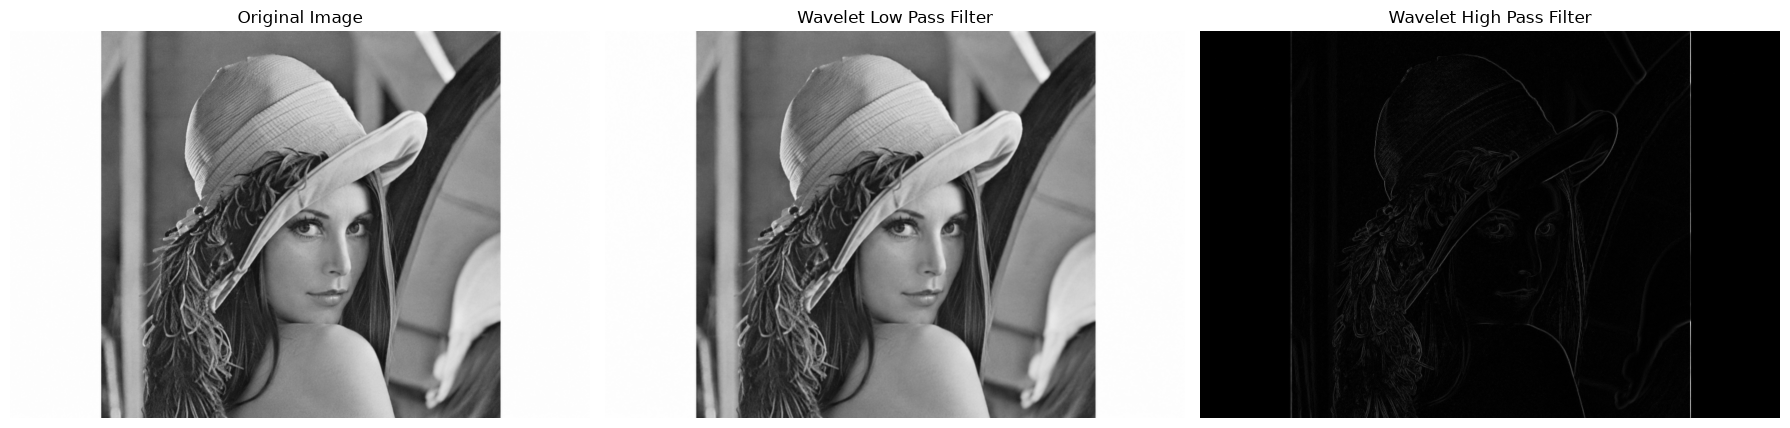

In [9]:
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_array, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_Low, cmap='gray', vmin=0, vmax=255)
plt.title("Wavelet Low Pass Filter")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_High, cmap='gray', vmin=0, vmax=255)
plt.title("Wavelet High Pass Filter")
plt.axis('off')

plt.tight_layout()
plt.show()